# 04 · Stacking ve ICECAT-1 alarmları

**Stacking:** Tek tek zayıf olan kaynakların sinyalleri ortak bir likelihood'da toplanır. Burada X-ışını parlak dört Seyfert galaksisi
(NGC 1068, NGC 4151, NGC 3079, CGCG 420-015) ortak $n_s$ ve $\gamma$ ile fit edilir.

**ICECAT-1:** IceCube'un gerçek zamanlı “gold/bronze” iz alarmlarının kataloğu ([doi:10.7910/DVN/SCRUCD](https://doi.org/10.7910/DVN/SCRUCD)).
DR2 ile aynı olay numaralandırmasını kullandığı için hangi alarmların iz örnekleminde bulunduğu doğrudan eşleştirilebilir.

In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

FIG = Path("../figures")
FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

from vcube.alerts import alerts_near, load_icecat, match_events
from vcube.data import PROCESSED_DIR, all_events
from vcube.pdfs import Model
from vcube.skymap import mollweide_xy, plot_mollweide
from vcube.sources import CANDIDATES, SEYFERT_STACK, StackingLLH, source
from vcube.trials import p_value, scrambled, sigma_from_p

model = Model()

## Seyfert stacking

In [2]:
stack = StackingLLH(model, SEYFERT_STACK)
fit = stack.fit()
print(f"TS = {fit['ts']:.2f}   n_s = {fit['ns']:.1f}   γ = {fit['gamma']:.2f}")

rng = np.random.default_rng(42)
bkg = np.array([stack.fit([l.prepare(scrambled(l, rng)) for l in stack.llhs])["ts"] for _ in range(300)])
p = p_value(fit["ts"], bkg)
print(f"p = {p:.2e} -> {sigma_from_p(p):.2f}σ   (300 deneme)")

TS = 55.41   n_s = 177.8   γ = 2.77


p = 9.21e-14 -> 7.36σ   (300 deneme)


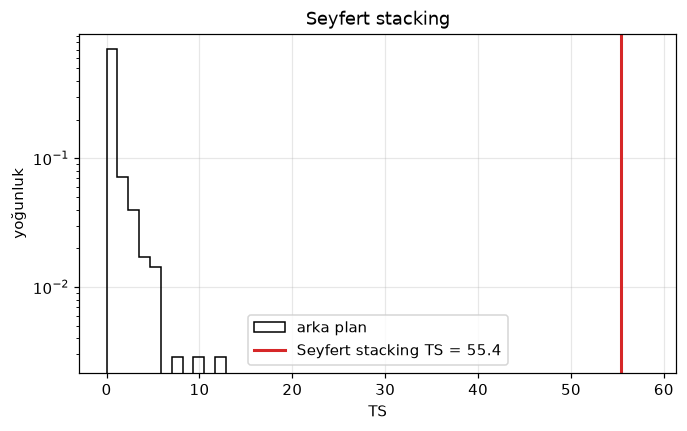

In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(bkg, bins=np.linspace(0, max(25, fit["ts"] + 3), 51), histtype="step", color="k", density=True, label="arka plan")
ax.axvline(fit["ts"], c="C3", lw=2, label=f"Seyfert stacking TS = {fit['ts']:.1f}")
ax.set(yscale="log", xlabel="TS", ylabel="yoğunluk", title="Seyfert stacking")
ax.legend()
fig.savefig(FIG / "04_stacking.png", bbox_inches="tight")

> **Uyarı — bu sayıları keşif olarak okumayın.**
> 1. Katalog *a posteriori* seçildi: NGC 4151, CGCG 420-015 ve NGC 3079, IceCube'un önceki analizlerinde zaten fazlalık gösteren Seyfert'lerdir. Sonucu bilinen kaynakları birleştirmek anlamlılığı yapay olarak büyütür; geçerli bir stacking testi, katalog veriye bakılmadan (ör. X-ışını akısına göre) seçilmelidir.
> 2. p-değeri 300 denemenin χ² kuyruğunun ekstrapolasyonudur; 5σ'nın ötesi bu deneme sayısıyla doğrulanamaz.
>
> Aşağıda NGC 1068 çıkarılınca da fazlalığın sürdüğü görülüyor — bu, diğer üç kaynağın bireysel ~3σ fazlalıklarının toplamıdır.

In [4]:
stack_wo = StackingLLH(model, [n for n in SEYFERT_STACK if n != "NGC 1068"])
fit_wo = stack_wo.fit()
bkg_wo = np.array([stack_wo.fit([l.prepare(scrambled(l, rng)) for l in stack_wo.llhs])["ts"] for _ in range(300)])
p_wo = p_value(fit_wo["ts"], bkg_wo)
print(f"NGC 1068 hariç: TS = {fit_wo['ts']:.2f}  n_s = {fit_wo['ns']:.1f}  γ = {fit_wo['gamma']:.2f}  p = {p_wo:.2e} ({sigma_from_p(p_wo):.2f}σ)")

NGC 1068 hariç: TS = 37.78  n_s = 121.6  γ = 2.71  p = 4.92e-09 (5.73σ)


## ICECAT-1 alarmları

In [5]:
alerts = load_icecat()
ev = all_events()
matched = match_events(alerts, ev)
print(f"{len(alerts)} alarm, bunların {len(matched)} tanesi DR2 iz örnekleminde de var.")
print(f"Gold: {(alerts.I3TYPE.str.contains('gold')).sum()}   Bronze: {(alerts.I3TYPE.str.contains('bronze')).sum()}")
matched[["NAME", "I3TYPE", "ENERGY", "SIGNAL", "err90_deg", "ang_err", "sep_deg", "logE"]].head(10)

348 alarm, bunların 293 tanesi DR2 iz örnekleminde de var.
Gold: 126   Bronze: 222


,NAME,I3TYPE,ENERGY,SIGNAL,err90_deg,ang_err,sep_deg,logE
0,IC110514A,gfu-gold,187.0,0.508,3.136001,0.26,1.407460,4.49
1,IC110610A,gfu-gold,294.0,0.750,1.418480,0.30,0.544031,4.53
2,IC110616A,gfu-bronze,109.0,0.257,1.288667,0.20,0.063011,4.27
3,IC110714A,hese-gold,72.0,0.778,0.487363,0.20,0.481331,4.87
4,IC110726A,gfu-bronze,160.0,0.396,1.172111,0.20,0.502252,4.70
5,IC110807A,gfu-bronze,108.0,0.266,1.262202,0.20,0.305002,4.35
6,IC110818A,gfu-bronze,123.0,0.340,1.007134,0.20,0.554757,4.38
7,IC110902A,gfu-gold,243.0,0.609,1.468344,0.20,0.033307,4.64
8,IC110907A,gfu-gold,186.0,0.506,2.277878,0.20,0.749365,4.48
9,IC110929A,gfu-bronze,158.0,0.521,0.519781,0.20,0.028459,4.20


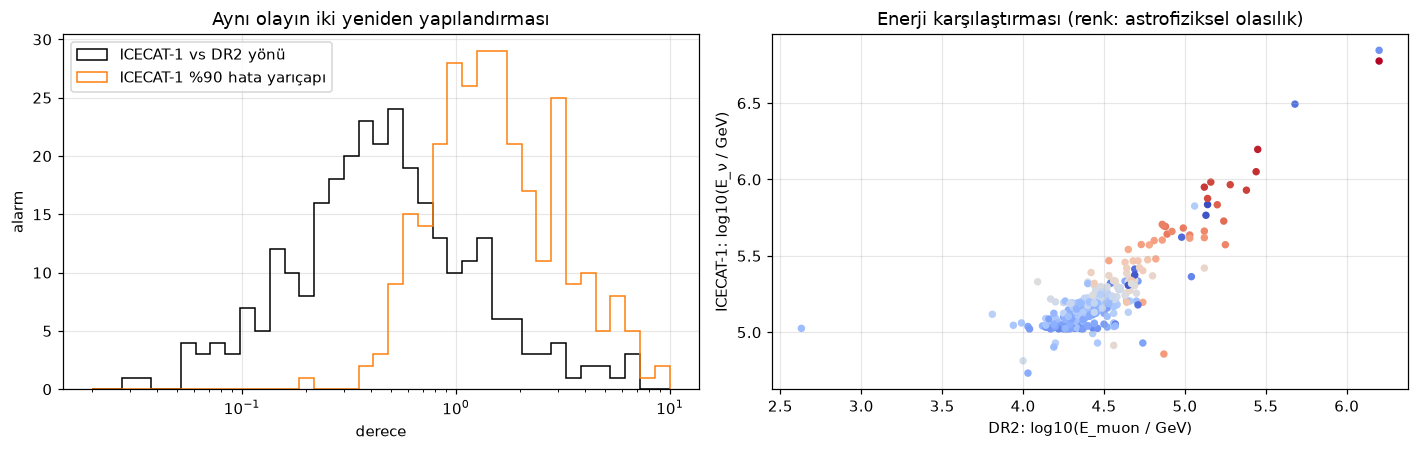

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].hist(matched.sep_deg, bins=np.logspace(-1.7, 1, 40), histtype="step", color="k", label="ICECAT-1 vs DR2 yönü")
axes[0].hist(matched.err90_deg, bins=np.logspace(-1.7, 1, 40), histtype="step", color="C1", label="ICECAT-1 %90 hata yarıçapı")
axes[0].set(xscale="log", xlabel="derece", ylabel="alarm", title="Aynı olayın iki yeniden yapılandırması")
axes[0].legend()

axes[1].scatter(matched.logE, np.log10(matched.ENERGY * 1e3), c=matched.SIGNAL, cmap="coolwarm", s=15)
axes[1].set(xlabel="DR2: log10(E_muon / GeV)", ylabel="ICECAT-1: log10(E_ν / GeV)", title="Enerji karşılaştırması (renk: astrofiziksel olasılık)")
fig.tight_layout()
fig.savefig(FIG / "04_icecat_eslesme.png", bbox_inches="tight")

In [7]:
rows = []
for name, ra, dec in CANDIDATES:
    for _, a in alerts_near(alerts, *source(name)).iterrows():
        rows.append({"kaynak": name, "alarm": a.NAME, "tür": a.I3TYPE, "E [TeV]": a.ENERGY,
                     "astrofiziksel olasılık": a.SIGNAL, "%90 yarıçap [°]": round(a.err90_deg, 2), "ayrım [°]": round(a.sep_deg, 2)})
pd.DataFrame(rows)

,kaynak,alarm,tür,E [TeV],astrofiziksel olasılık,%90 yarıçap [°],ayrım [°]
0,TXS 0506+056,IC170922A,gfu-gold,264.0,0.631,0.73,0.12
1,TXS 0506+056,IC220918A,gfu-bronze,168.0,0.418,3.79,3.05
2,TXS 0506+056,IC190317A,gfu-bronze,108.0,0.260,4.96,4.60
3,CGCG 420-015,IC220918A,gfu-bronze,168.0,0.418,3.79,1.85
4,Mrk 421,IC111208A,gfu-bronze,123.0,0.446,3.97,0.77


**IC170922A** — 22 Eylül 2017'de yayımlanan bu alarm, γ-ışını parlaması gösteren blazar **TXS 0506+056** ile çakıştı; ilk nötrino kaynağı kanıtıydı ([Science 361, eaat1378](https://doi.org/10.1126/science.aat1378)).

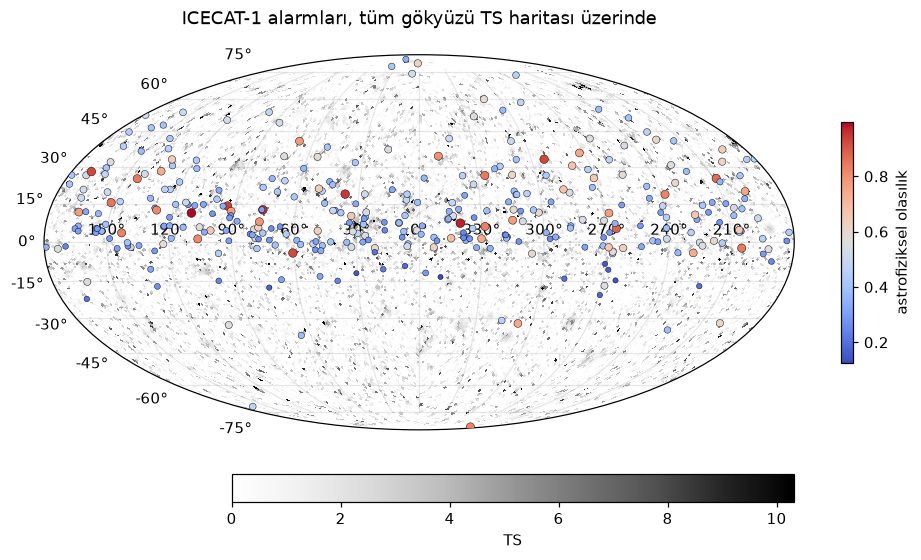

In [8]:
sky_path = PROCESSED_DIR / "skymap_nside64.npz"
if sky_path.exists():
    sky = dict(np.load(sky_path))
    ax = plot_mollweide(np.nan_to_num(sky["ts"]), int(sky["nside"]), cmap="Greys", vmax=np.nanpercentile(sky["ts"], 99.9))
else:
    _, ax = plt.subplots(figsize=(11, 6), subplot_kw={"projection": "mollweide"})
x, y = mollweide_xy(alerts.ra_rad, alerts.dec_rad)
sc = ax.scatter(x, y, c=alerts.SIGNAL, s=8 + 25 * alerts.SIGNAL, cmap="coolwarm", edgecolor="k", lw=0.3, zorder=3)
plt.colorbar(sc, ax=ax, orientation="vertical", shrink=0.6, label="astrofiziksel olasılık")
ax.set_title("ICECAT-1 alarmları, tüm gökyüzü TS haritası üzerinde", pad=20)
plt.gcf().savefig(FIG / "04_icecat_gok.png", bbox_inches="tight")